# Tavily MCP Server

https://docs.tavily.com/documentation/mcp

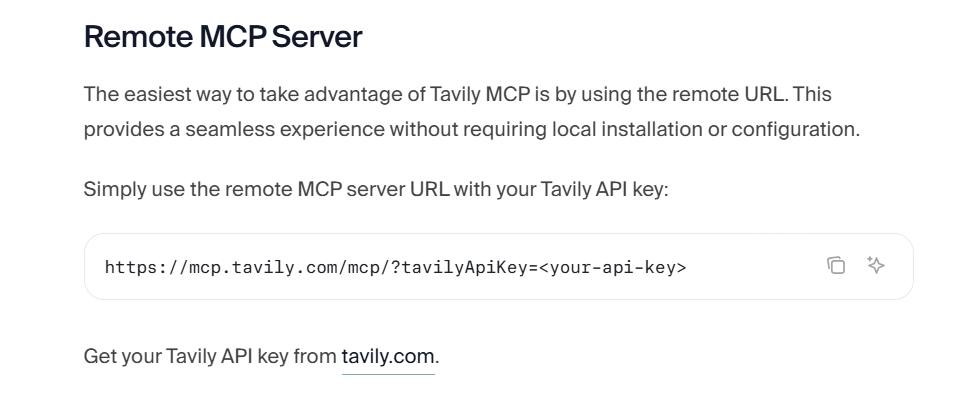

# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 20ms


In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# MCP Client agent 활용

## 간단 버전

In [3]:
# .env 파일을 읽어 환경변수로 등록한다
load_dotenv()

# 환경변수에서 Tavily API 키를 읽어온다
TAVILY_API_KEY = os.environ.get("TAVILY_API_KEY")

In [4]:
# 여러 MCP 서버에 연결할 수 있는 클라이언트를 가져온다
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.agents import create_agent



# "tavily" 서버에 HTTP 전송 방식으로 연결하는 클라이언트를 생성한다
client = MultiServerMCPClient(
    {
        "tavily": {
            "transport": "streamable_http",
            # URL 쿼리 파라미터로 Tavily API 키를 전달한다 (끝에 슬래시 포함)
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}",
        }
    }
)

# 서버의 MCP 도구들을 LangChain 도구로 가져온다
tools = await client.get_tools()

# 도구를 사용하는 에이전트를 생성한다
agent = create_agent("openai:gpt-5-mini", tools)
# 에이전트에 질문을 전달하고 응답을 받는다
agent_response = await agent.ainvoke({"messages": " 오늘 서울 날씨"})

for m in agent_response["messages"]:
    m.pretty_print()

================================ Human Message =================================

 오늘 서울 날씨
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_GbFhQIDz2YAs2c1InKscZ4df)
 Call ID: call_GbFhQIDz2YAs2c1InKscZ4df
  Args:
    query: 오늘 서울 날씨
    max_results: 5
    search_depth: fast
    time_range: day
    topic: general
    include_favicon: False
================================= Tool Message =================================
Name: tavily_search

[{'type': 'text', 'text': '{"query":"오늘 서울 날씨","follow_up_questions":null,"answer":null,"images":[],"results":[{"url":"https://sharpweather.com/ko/seoul/today","title":"오늘 서울 날씨 - 오늘 서울 날씨 시간별","content":"오늘 서울 날씨 - 오늘 서울 날씨 시간별\\n\\nTitle: 오늘 서울 날씨 - 오늘 서울 날씨 시간별\\n# 오늘 서울 날씨. 바람:  서, 2.8 m/s. 북, 1.4 m/s. 하루 기간 11 h 22 min. ## 오늘 서울 날씨 시간별. 바람:  북동, 1.7 m/s. 북동, 1.2 m/s. 북, 0.9 m/s. 북, 1.1 m/s. 북, 1.4 m/s. 북, 1.7 m/s. 북, 1.7 m/s. 북, 1.6 m/s. 북, 2.1 m/s. 북서, 1.4 m/s. 북서, 1.9 m/s. 서, 2

## 도구 활용 확인 버전

In [13]:
# 여러 MCP 서버에 연결할 수 있는 클라이언트를 가져온다
from langchain_mcp_adapters.client import MultiServerMCPClient
# 도구를 사용하는 에이전트를 생성하는 함수를 가져온다
from langchain.agents import create_agent
# 응답 메시지의 타입을 판별하기 위해 메시지 클래스를 가져온다
from langchain_core.messages import AIMessage, ToolMessage

# "tavily" 서버에 HTTP 전송 방식으로 연결하는 클라이언트를 생성한다
client = MultiServerMCPClient(
    {
        "tavily": {
            "transport": "streamable_http",
            # URL 쿼리 파라미터로 Tavily API 키를 전달한다 (끝에 슬래시 포함)
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}",
        }
    }
)

# 원격 MCP 서버에 접속하여 서버가 제공하는 도구들을 LangChain 도구 객체로 가져온다
tools = await client.get_tools()

# 원격 서버에서 도구를 실제로 받아왔는지 확인한다 (도구 개수 출력)
print(f"[연결 확인] 원격 MCP 서버에서 가져온 도구 개수: {len(tools)}")
for t in tools:
    # 로드된 각 도구의 이름을 출력한다
    print(f"  - 로드된 도구 이름: {t.name}")

# 로드된 도구 이름을 집합으로 저장하여, 나중에 호출된 도구가 MCP 도구인지 대조한다
mcp_tool_names = {t.name for t in tools}

# 원격 MCP 서버에서 가져온 도구를 사용하는 에이전트를 생성한다
agent = create_agent("openai:gpt-5-mini", tools)

# 이번 실행에서 원격 MCP 도구가 실제로 호출되었는지 여부를 저장할 변수
used_remote_mcp = False


[연결 확인] 원격 MCP 서버에서 가져온 도구 개수: 5
  - 로드된 도구 이름: tavily_search
  - 로드된 도구 이름: tavily_extract
  - 로드된 도구 이름: tavily_crawl
  - 로드된 도구 이름: tavily_map
  - 로드된 도구 이름: tavily_research


In [14]:
# stream_mode=["updates", "messages"]로 두 종류의 스트림을 동시에 받는다
# - "messages": LLM이 생성하는 토큰을 실시간으로 흘려보낸다 (실시간 텍스트 출력용)
# - "updates" : 각 노드 실행이 끝날 때마다 완성된 메시지를 보낸다 (도구 사용 판정용)
async for mode, chunk in agent.astream(
    {"messages": "오늘 서울 날씨 알려주세요"},
    stream_mode=["updates", "messages"],
):
    # 토큰 단위 스트림인 경우: (토큰, 메타데이터) 튜플이 들어온다
    if mode == "messages":
        # chunk를 토큰과 메타데이터로 분리한다
        token, metadata = chunk
        # 도구 실행 결과(ToolMessage)가 아니고 실제 텍스트 내용이 있으면 실시간으로 출력한다
        if token.content and not isinstance(token, ToolMessage):
            # 줄바꿈 없이 이어붙여 출력하고 즉시 화면에 반영한다
            print(token.content, end="", flush=True)

    # 노드 단위 스트림인 경우: {노드이름: {상태키: 값}} 형태의 딕셔너리가 들어온다
    elif mode == "updates":
        # 각 노드가 갱신한 메시지들을 순회하며 도구 사용 흔적을 검사한다
        for node_name, node_update in chunk.items():
            # 해당 노드가 반환한 메시지 목록을 꺼낸다 (없으면 빈 리스트)
            for m in node_update.get("messages", []):
                # 모델이 도구 호출을 요청한 메시지인지 확인한다
                if isinstance(m, AIMessage) and m.tool_calls:
                    for call in m.tool_calls:
                        # 호출한 도구가 원격 MCP 서버에서 로드한 도구인지 대조한다
                        if call["name"] in mcp_tool_names:
                            # 원격 MCP 도구 호출이 확인되었으므로 플래그를 설정한다
                            used_remote_mcp = True
                            # 실시간 텍스트와 섞이지 않도록 줄바꿈 후 호출 정보를 출력한다
                            print(f"\n[호출 감지] MCP 도구 호출: {call['name']} / 인자: {call['args']}")
                # 도구 실행 결과가 돌아온 메시지인지 확인한다
                if isinstance(m, ToolMessage) and m.name in mcp_tool_names:
                    # 원격 MCP 도구가 실제로 실행되었으므로 플래그를 설정한다
                    used_remote_mcp = True
                    # 어떤 도구의 결과가 수신되었는지 출력한다
                    print(f"\n[실행 결과] MCP 도구 '{m.name}'의 실행 결과를 수신함")

# 스트리밍이 끝난 뒤, 이번 응답에서 원격 MCP 서버 도구가 사용되었는지 최종 출력한다
print(f"\n[판정] 이번 응답에서 원격 MCP 서버 도구 사용 여부: {used_remote_mcp}")


[호출 감지] MCP 도구 호출: tavily_search / 인자: {'query': 'Seoul weather today', 'max_results': 5, 'search_depth': 'fast', 'topic': 'general', 'time_range': 'day', 'include_images': False}

[실행 결과] MCP 도구 'tavily_search'의 실행 결과를 수신함

[호출 감지] MCP 도구 호출: tavily_search / 인자: {'query': '서울 오늘 날씨 기상청', 'max_results': 5, 'search_depth': 'fast', 'topic': 'general', 'time_range': 'day', 'include_images': False}

[실행 결과] MCP 도구 'tavily_search'의 실행 결과를 수신함

[호출 감지] MCP 도구 호출: tavily_search / 인자: {'query': '기상청 서울 현재 날씨 서울특별시 오늘 기온', 'max_results': 5, 'search_depth': 'fast', 'topic': 'general', 'time_range': 'day', 'include_images': False}

[실행 결과] MCP 도구 'tavily_search'의 실행 결과를 수신함

[호출 감지] MCP 도구 호출: tavily_search / 인자: {'query': '서울 현재 날씨 지금 기온 기상청', 'max_results': 5, 'search_depth': 'fast', 'topic': 'general', 'time_range': 'day', 'include_images': False}

[실행 결과] MCP 도구 'tavily_search'의 실행 결과를 수신함
어떤 정보를 원하시나요? (간단히 골라주세요)

- 지금 현재 기온·강수 여부·체감온도(지금 바로 확인)  
- 오늘 하루 종합 예보(최저/최고기온, 강수확률, 시간대별)  
- 시간별

# LangGraph 활용 

In [8]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition
from langchain.chat_models import init_chat_model
from langchain.messages import SystemMessage


model = init_chat_model("openai:gpt-5.4-mini")

# "tavily" 서버에 HTTP 전송 방식으로 연결하는 클라이언트를 생성한다
client = MultiServerMCPClient(
    {
        "tavily": {
            "transport": "streamable_http",
            # URL 쿼리 파라미터로 Tavily API 키를 전달한다 (끝에 슬래시 포함)
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}",
        }
    }
)
tools = await client.get_tools()          # 주피터 top-level await
print(f"사용 가능한 Tools: {[t.name for t in tools]}")

사용 가능한 Tools: ['tavily_search', 'tavily_extract', 'tavily_crawl', 'tavily_map', 'tavily_research']


In [9]:
# LLM 노드: 시스템 지침 + 대화 메시지로 응답 생성 (필요 시 Tool 호출 결정)
def call_model(state: MessagesState):
    system_message = SystemMessage(
        content="""당신은 Tavily 웹 검색 도구를 사용해 실시간 정보를 바탕으로 질문에 답변하는 AI 어시스턴트입니다.
웹 검색 도구로 최신·정확한 정보를 찾아 제공하고, 답변에는 참고한 출처 url을 포함하며 한국어로 설명하세요."""
    )
    # 매 호출마다 시스템 메시지를 앞에 붙여 전달
    response = model.bind_tools(tools).invoke([system_message] + state["messages"])
    return {"messages": response}

# 그래프 구성: call_model ↔ tools 반복
builder = StateGraph(MessagesState)
builder.add_node(call_model)                       # 노드명 = 함수명 "call_model"
builder.add_node(ToolNode(tools))                  # 노드명 = 기본값 "tools"
builder.add_edge(START, "call_model")
builder.add_conditional_edges("call_model", tools_condition)  # tool_calls 있으면 "tools", 없으면 종료
builder.add_edge("tools", "call_model")            # Tool 실행 후 다시 LLM으로
graph = builder.compile()

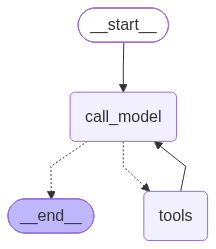

In [10]:
graph 

In [11]:
# stream_mode="messages": LLM 토큰을 (토큰, 메타데이터) 튜플로 실시간 스트리밍
async for msg, metadata in graph.astream(
    {"messages": "오늘 서울 날씨 알려주세요"},   # 질문은 이 문자열만 바꾸면 됨
    stream_mode="messages",
):
    # call_model 노드의 토큰만 즉시 출력 (tools 노드의 검색 원문은 제외)
    if msg.content and metadata.get("langgraph_node") == "call_model":
        print(msg.content, end="", flush=True)

오늘 서울 날씨는 **비가 오고, 천둥·번개 가능성도 있는 흐린 날씨**로 보입니다.

- **현재 기온:** 약 **26°C**
- **오늘 낮 최고:** 약 **28°C**
- **오늘 밤 기온:** 약 **24~25°C**
- **강수:** 비가 내리고, 시간대에 따라 **천둥을 동반한 비** 가능성
- **바람:** 약 **6~15 km/h**
- **습도:** 매우 높음(약 **84~95% 이상**)

시간대별로 보면 **오전~오후에 비가 이어지고**, 저녁에도 비가 올 가능성이 있습니다.

참고한 출처:
- https://freemeteo.kr/weather/seoul/daily-forecast/today?gid=1835848&language=korean&country=south-korea

원하시면 제가 **“오늘 서울 날씨를 시간대별로”** 더 자세히 정리해드릴게요.